In [ ]:
import os
import json
import numpy as np
import pandas as pd

from tqdm import tqdm
from collections import Counter
# from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectFromModel
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler


import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))

# Read the files

In [18]:
root_folder = "C:/Users/Muhammad.Dehan/Repository/prompt-fairness/annotation_artefacts/final_annotator_objects"

rows = []

# walk through all subdirectories and files
for subdir, _, files in os.walk(root_folder):
    for file in files:
        if file.endswith(".json"):  # only JSON files
            file_path = os.path.join(subdir, file)
            with open(file_path, 'r', encoding='utf-8') as f:
                data = json.load(f)
            
            # extract common fields
            # annot_id = data.get("id")
            profile = data.get("profile", {})

            # answers are a dict of dicts
            answers = data.get("answers", {})
            for q_key, answer_obj in answers.items():
                # skip if answer is None or empty string
                answer_text = answer_obj.get("answer")
                if answer_text is None or (isinstance(answer_text, str) and answer_text.strip() == ""):
                    continue  # skip this one

                row = {}
                # row["id"] = annot_id

                # add profile columns
                for k, v in profile.items():
                    row[k] = v

                # add answer fields
                row["answer"] = answer_obj.get("answer")
                row["sentence_type"] = answer_obj.get("sentence_type")
                row["grammaticality"] = answer_obj.get("grammaticality")

                rows.append(row)

df = pd.DataFrame(rows)

df.sample(2)
# df.to_csv("annotations_flattened.csv", index=False)

,employment_sector,race,education,sex,age,language,nationality_group,answer,sentence_type,grammaticality
1758,Engineering-STEM,White,Postgraduate,female,18-30,L1,Europe,Identify specific words or phrases in the sent...,imperative,correct
2462,Health-STEM,White,Graduate,female,41-50,L1,Europe,Please tell me about Hilary Clintons achieveme...,imperative,incorrect


# Extract Text Features

In [25]:
def extract_text_features(text):
    if not isinstance(text, str) or text.strip() == "":
        # return NaNs or zeros for empty values
        return pd.Series({
            "self_ref_freq": np.nan,
            "num_words": 0,
            "num_chars": 0,
            "num_capital_words": 0,
            "num_stopwords": 0,
            "num_exclamation": 0,
            "num_question": 0,
            "num_nouns": 0,
            "num_verbs": 0,
            "num_adjectives": 0,
            "num_adverbs": 0,
            "num_pronouns": 0,
            "ttr": np.nan,
            "avg_word_length": np.nan,
            "num_short_words": 0,
            "num_long_words": 0,
            "num_numeric": 0
        })

    # Tokenize
    tokens = word_tokenize(text)
    words = [w for w in tokens if w.isalpha() or w.isalnum()]  # keep alphanumeric
    num_words = len(words)
    if num_words == 0:
        num_words = 1  # avoid division by zero

    # Self-reference pronouns
    self_refs = {"i", "me", "my", "mine", "myself",
                 "we", "us", "our", "ours", "ourselves",
                 "team"} # add more if we have any more idea
    self_ref_count = sum(1 for w in words if w.lower() in self_refs)
    self_ref_freq = self_ref_count / num_words

    # Characters (excluding spaces)
    num_chars = len(text.replace(" ", ""))

    # Capital words (fully uppercase and length>1)
    num_capital_words = sum(1 for w in words if w.isupper() and len(w) > 1)

    # Stopwords
    num_stopwords = sum(1 for w in words if w.lower() in stop_words)

    # Punctuation marks
    num_exclamation = text.count("!")
    num_question = text.count("?")

    # POS tagging
    tagged = nltk.pos_tag(words)
    pos_counts = Counter(tag for _, tag in tagged)
    # Map Penn Treebank POS to broad categories
    num_nouns = sum(pos_counts[t] for t in pos_counts if t.startswith('NN'))
    num_verbs = sum(pos_counts[t] for t in pos_counts if t.startswith('VB'))
    num_adjectives = sum(pos_counts[t] for t in pos_counts if t.startswith('JJ'))
    num_adverbs = sum(pos_counts[t] for t in pos_counts if t.startswith('RB'))
    num_pronouns = sum(pos_counts[t] for t in pos_counts if t in {'PRP','PRP$','WP','WP$'})

    # Type-Token Ratio (TTR)
    unique_words = len(set(w.lower() for w in words))
    ttr = unique_words / num_words

    # Average word length
    avg_word_length = np.mean([len(w) for w in words])

    # Short and long words
    num_short_words = sum(1 for w in words if len(w) <= 3)
    num_long_words = sum(1 for w in words if len(w) >= 7)

    # Numeric tokens
    num_numeric = sum(1 for w in tokens if any(ch.isdigit() for ch in w))

    return pd.Series({
        "self_ref_freq": self_ref_freq,
        "num_words": num_words,
        "num_chars": num_chars,
        "num_capital_words": num_capital_words,
        "num_stopwords": num_stopwords,
        "num_exclamation": num_exclamation,
        "num_question": num_question,
        "num_nouns": num_nouns,
        "num_verbs": num_verbs,
        "num_adjectives": num_adjectives,
        "num_adverbs": num_adverbs,
        "num_pronouns": num_pronouns,
        "ttr": ttr,
        "avg_word_length": avg_word_length,
        "num_short_words": num_short_words,
        "num_long_words": num_long_words,
        "num_numeric": num_numeric
    })


In [30]:
features_df = df['answer'].apply(extract_text_features)
df = pd.concat([df, features_df], axis=1)

In [32]:
df.sample(2)

,employment_sector,race,education,sex,age,language,nationality_group,answer,sentence_type,grammaticality,...,num_nouns,num_verbs,num_adjectives,num_adverbs,num_pronouns,ttr,avg_word_length,num_short_words,num_long_words,num_numeric
1073,Engineering-STEM,Asian,Graduate,male,18-30,L2,Asia,Preform semantic similarity on the given two s...,imperative,incorrect,...,11.0,3.0,2.0,0.0,0.0,0.896552,5.137931,12.0,12.0,6.0
1286,Engineering-STEM,Asian,Postgraduate,male,18-30,L2,Africa,Please help he fix the typos and errors here: ...,imperative,correct,...,39.0,34.0,9.0,12.0,17.0,0.660131,4.130719,74.0,28.0,1.0


# Prepare The Dataset

In [37]:
from copy import deepcopy

df_2 = deepcopy(df)

In [ ]:
# label encode and normalize
special_cols = ['employment_sector', 'race', 'education', 
                'sex', 'age', 'language', 'nationality_group']

label_mappings = {}
for col in special_cols:
    if col in df_2.columns:
        le = LabelEncoder()
        df_2[col] = le.fit_transform(df_2[col].astype(str))
        label_mappings[col] = {class_: int(code) for class_, code in zip(le.classes_, le.transform(le.classes_))}

ignore_cols = ['answer']  
other_cols = [col for col in df_2.columns if col not in special_cols + ignore_cols]
cat_cols = [col for col in other_cols if df_2[col].dtype == 'object']
for col in cat_cols:
    le = LabelEncoder()
    df_2[col] = le.fit_transform(df_2[col].astype(str))

num_cols = [col for col in df_2.columns if col != 'answer' and col not in special_cols]
scaler = MinMaxScaler()
df_2[num_cols] = scaler.fit_transform(df_2[num_cols])

In [39]:
df_2.sample(2)

,employment_sector,race,education,sex,age,language,nationality_group,answer,sentence_type,grammaticality,...,num_nouns,num_verbs,num_adjectives,num_adverbs,num_pronouns,ttr,avg_word_length,num_short_words,num_long_words,num_numeric
2105,2,2,1,1,0,0,4,Write me a letter to be submitted asking for h...,0.5,1.0,...,0.203704,0.10,0.214286,0.0,0.071429,0.435897,0.440807,0.174757,0.285714,0.0
1808,1,3,2,0,0,0,4,What do the phrases from the adhan mean in eng...,1.0,1.0,...,0.018519,0.02,0.142857,0.0,0.035714,0.800000,0.276596,0.038835,0.047619,0.0


# Find the top-5 features for each categories

In [ ]:
special_cols = ['employment_sector', 'race', 'education', 'sex', 'age', 'language', 'nationality_group']

X = df_2.drop(columns=special_cols + ['answer'])

In [66]:
def get_top_features(X, y, top_k=5):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = LinearSVC(random_state=42, max_iter=5000)
    clf.fit(X_scaled, y)

    # absolute value of coefficients indicates importance
    coef = np.abs(clf.coef_)
    if len(coef.shape) == 1:
        importance = coef
    else:
        importance = coef.mean(axis=0)

    feature_importance = pd.Series(importance, index=X.columns)
    return feature_importance.sort_values(ascending=False).head(top_k)

def get_top_features_sfm(X, y, top_k=5, random_state=42, threshold='median'):
    """
    Returns the top_k features selected by SelectFromModel using LinearSVC.
    
    X : pd.DataFrame of features
    y : pd.Series target
    top_k : int, number of top features to return
    threshold : str or float, threshold for SelectFromModel ('median', 'mean', or float value)
    """
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = LinearSVC(random_state=random_state, max_iter=5000)
    clf.fit(X_scaled, y)

    sfm = SelectFromModel(clf, threshold=threshold, prefit=True)
    selected_features = X.columns[sfm.get_support()]

    coefs = pd.Series(abs(clf.coef_).mean(axis=0), index=X.columns)
    top_features = coefs[selected_features].sort_values(ascending=False).head(top_k)
    
    return top_features

def get_top_features_sfm_2(X, y, top_k=5, random_state=42):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = LinearSVC(random_state=random_state, max_iter=5000)
    clf.fit(X_scaled, y)

    # take absolute mean of coefficients across classes
    coefs = pd.Series(abs(clf.coef_).mean(axis=0), index=X.columns)
    top_features = coefs.sort_values(ascending=False).head(top_k)
    
    return top_features


def get_top_features_rf(X, y, top_k=5, random_state=42, threshold='median'):
    """
    Returns the top_k features selected by SelectFromModel using LinearSVC.
    
    X : pd.DataFrame of features
    y : pd.Series target
    top_k : int, number of top features to return
    threshold : str or float, threshold for SelectFromModel ('median', 'mean', or float value)
    """
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = RandomForestClassifier(random_state=random_state, n_estimators=500)
    clf.fit(X_scaled, y)

    feature_importance = pd.Series(clf.feature_importances_, index=X.columns)
    top_features = feature_importance.sort_values(ascending=False).head(top_k)
    
    return top_features

In [81]:
top_features_dict = {}

for target in tqdm(special_cols):
    y = df_2[target]
    top_feats = get_top_features_sfm_2(X, y, top_k=5)
    top_features_dict[target] = top_feats
    # print(f"Top 5 features for {target}:\n{top_feats}\n")

100%|██████████| 7/7 [00:00<00:00, 38.30it/s]


# Viz

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [87]:
plot_data = []

for target, features in top_features_dict.items():
    features_sorted = features[features > 0].sort_values(ascending=False).head(5)
    for feature, importance in features_sorted.items():
        plot_data.append({
            "Target": target,
            "Feature": feature,
            "Importance": importance
        })

plot_df = pd.DataFrame(plot_data)

targets = plot_df['Target'].unique()
num_targets = len(targets)

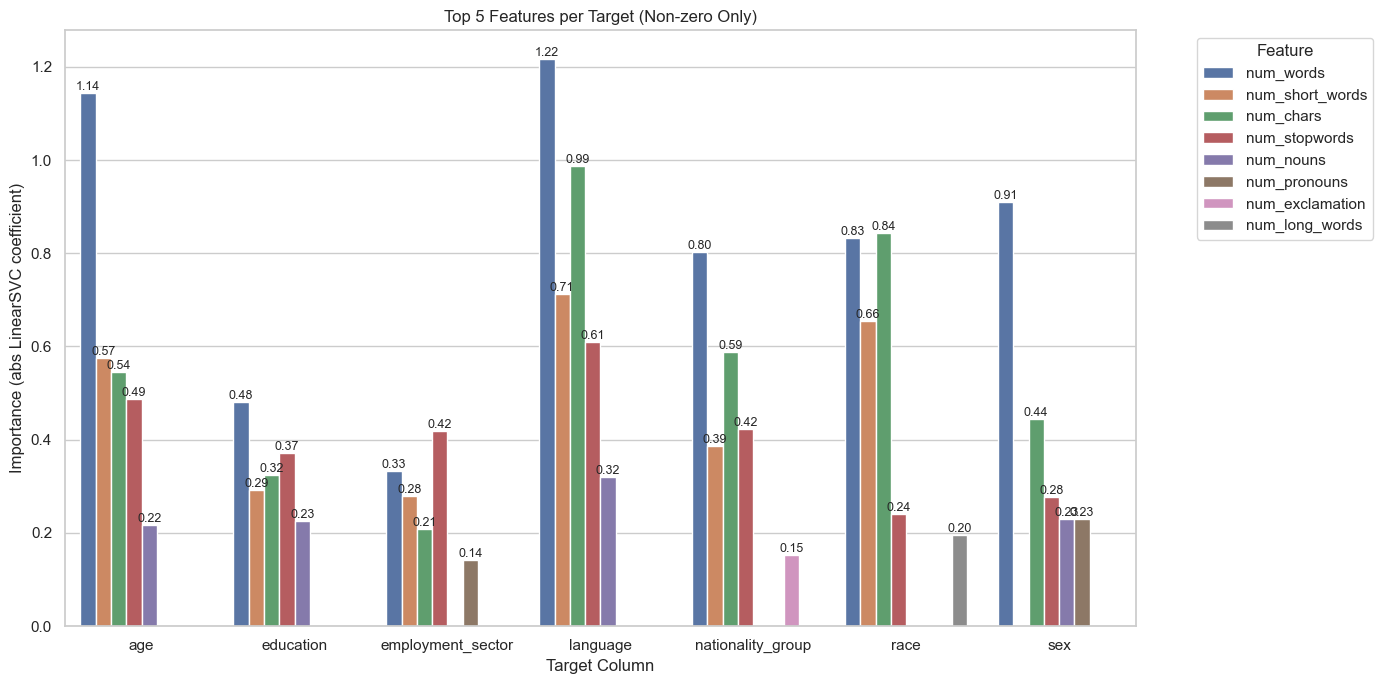

In [ ]:
plt.figure(figsize=(14, 7))

# Sort by importance within each target
plot_df = plot_df.sort_values(['Target', 'Importance'], ascending=[True, False])

ax = sns.barplot(
    data=plot_df,
    x="Target",
    y="Importance",
    hue="Feature",
    dodge=True
)

# Annotate bars with importance values
for p in ax.patches:
    height = p.get_height()
    if height > 0: 
        ax.annotate(
            f"{height:.2f}", 
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, rotation=0
        )

plt.title("Top 5 Features per Target (Non-zero Only)")
plt.ylabel("Importance (abs LinearSVC coefficient)")
plt.xlabel("Target Column")
plt.legend(title="Feature", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

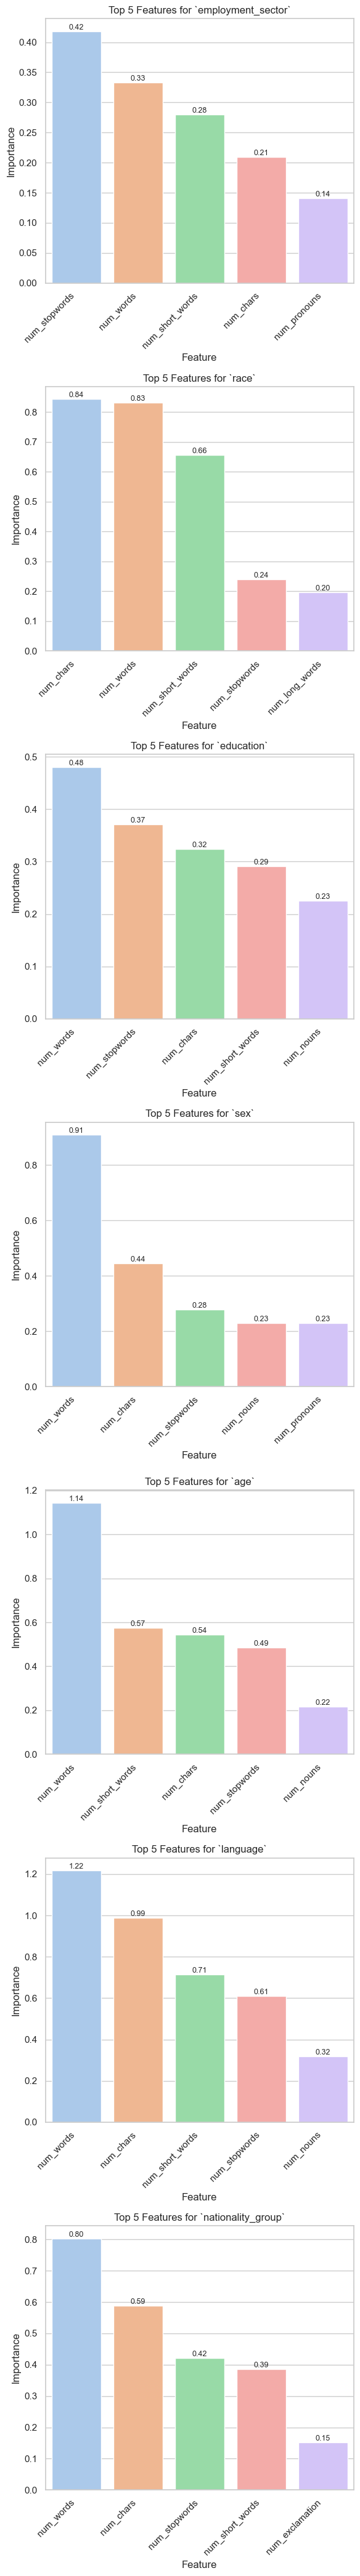

In [ ]:
fig, axes = plt.subplots(num_targets, 1, figsize=(6, 6*num_targets), sharey=False)

if num_targets == 1:
    axes = [axes]  # Make it iterable if only 1 target

for ax, target in zip(axes, targets):
    df_target = plot_df[plot_df['Target'] == target].sort_values('Importance', ascending=False)
    
    sns.barplot(
        data=df_target,
        x='Feature',
        y='Importance',
        hue='Feature',
        ax=ax,
        palette="pastel",
        legend=False
    )
    
    # Annotate bars
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f"{height:.2f}",
                    (p.get_x() + p.get_width()/2, height),
                    ha='center', va='bottom',
                    fontsize=9)
    
    ax.set_title(f"Top 5 Features for `{target}`")
    ax.set_xlabel("Feature")
    ax.set_ylabel("Importance")
    ax.set_xticks([i for i in range(len(ax.get_xticklabels()))])
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()